# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd
from pathlib import Path
from src.config import carpeta_datos
from src.modeling import cargar_datos
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    pintar_matriz_correlacion 
)

# Cargar fichero de precios
simbolo = 'SPY'
intervalo = '1d'
df, cols_exclude = cargar_datos(simbolo=simbolo, intervalo=intervalo, leer_cols_exclude=True)
df_clean = df.drop(columns=cols_exclude)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5186 entries, 2006-03-16 00:00:00-05:00 to 2026-10-26 00:00:00-04:00
Data columns (total 13 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Close_lag1_sma20_pct_diff_Close_lag1_sma50  5186 non-null   float64
 1   Volume_lag1_pct_diff_Volume_lag1_sma20      5186 non-null   float64
 2   Close_lag1_min20_pct_diff_Open              5186 non-null   float64
 3   High_pct_diff_Open                          5186 non-null   float64
 4   Low_pct_diff_Open                           5186 non-null   float64
 5   Close_pct_diff_Open                         5186 non-null   float64
 6   Low_lag1_pct_diff_Open                      5186 non-null   float64
 7   Close_lag1_pct_diff_Open                    5186 non-null   float64
 8   Close_lag1_sma50_pct_diff_Open              5186 non-null   float64
 9   Daily_return_lag1                    

In [7]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [8]:
# Descripcion de variables
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Close_lag1_sma20_pct_diff_Close_lag1_sma50,5186.0,0.006335,0.024622,-0.148874,-0.003612,0.010529,0.020879,0.073720
Volume_lag1_pct_diff_Volume_lag1_sma20,5186.0,0.015748,0.378045,-0.828455,-0.232436,-0.060673,0.165605,3.319121
Close_lag1_min20_pct_diff_Open,5186.0,-0.034596,0.027386,-0.218761,-0.047612,-0.031495,-0.016689,0.076135
High_pct_diff_Open,5186.0,0.005959,0.006942,0.000000,0.001890,0.004070,0.007652,0.111827
Low_pct_diff_Open,5186.0,-0.006465,0.007459,-0.096852,-0.008327,-0.004292,-0.001829,0.000000
Close_pct_diff_Open,5186.0,0.000155,0.009356,-0.089906,-0.003560,0.000574,0.004455,0.111827
Low_lag1_pct_diff_Open,5186.0,-0.006853,0.010084,-0.140878,-0.010197,-0.005465,-0.001842,0.058125
Close_lag1_pct_diff_Open,5186.0,-0.000276,0.007389,-0.057782,-0.003422,-0.000581,0.002374,0.116676
Close_lag1_sma50_pct_diff_Open,5186.0,-0.009133,0.043741,-0.132746,-0.034655,-0.018040,0.004857,0.403588
Daily_return_lag1,5186.0,0.000487,0.012121,-0.109424,-0.003966,0.000691,0.005906,0.145197


In [9]:
# Asimetrias
mostrar_asimetrias(df_clean)

High_pct_diff_Open                            4.242642
Close_lag1_sma50_pct_diff_Open                2.728440
Volume_lag1_pct_diff_Volume_lag1_sma20        1.987102
Close_lag1_pct_diff_Open                      1.720019
Daily_return_lag1_var20_log                   0.653059
Close_lag1_max20_pct_diff_Open_yeo            0.457418
Daily_return_lag1                            -0.001054
Close_pct_diff_Open                          -0.025537
High_lag1_pct_diff_Open_yeo                  -0.506563
Close_lag1_min20_pct_diff_Open               -1.471325
Close_lag1_sma20_pct_diff_Close_lag1_sma50   -1.797948
Low_lag1_pct_diff_Open                       -2.392955
Low_pct_diff_Open                            -3.436176


Cont


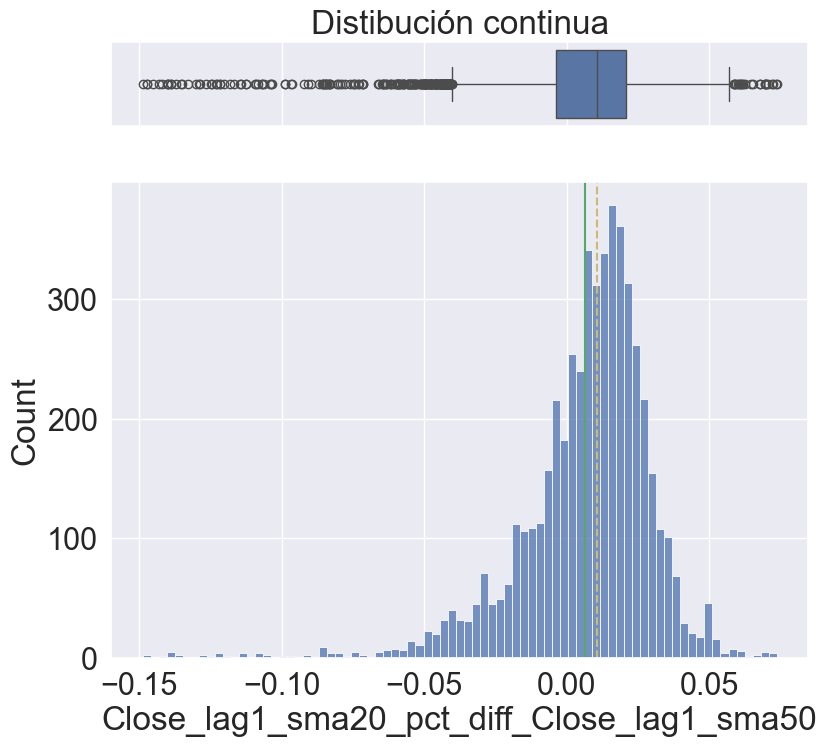

In [10]:
# Visualizar columna
col = 'Close_lag1_sma20_pct_diff_Close_lag1_sma50'
pintar_columna(df_clean[col])

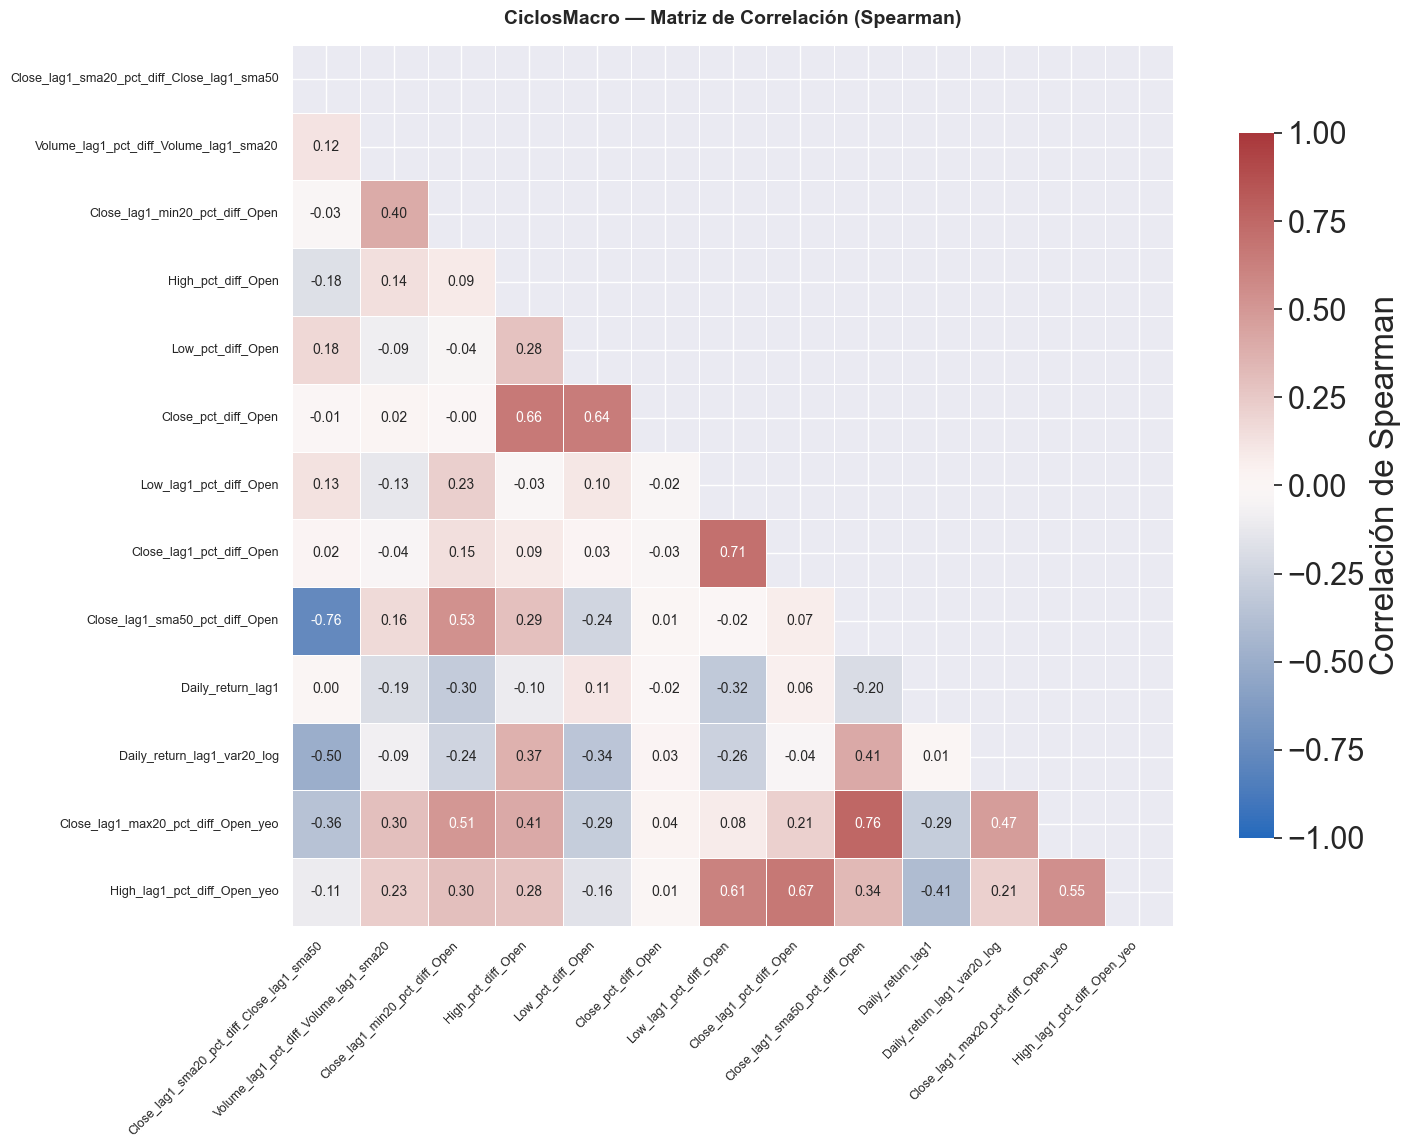

(                                            Close_lag1_sma20_pct_diff_Close_lag1_sma50  \
 Close_lag1_sma20_pct_diff_Close_lag1_sma50                                    1.000000   
 Volume_lag1_pct_diff_Volume_lag1_sma20                                        0.119510   
 Close_lag1_min20_pct_diff_Open                                               -0.029513   
 High_pct_diff_Open                                                           -0.177279   
 Low_pct_diff_Open                                                             0.177880   
 Close_pct_diff_Open                                                          -0.006125   
 Low_lag1_pct_diff_Open                                                        0.131606   
 Close_lag1_pct_diff_Open                                                      0.024506   
 Close_lag1_sma50_pct_diff_Open                                               -0.761317   
 Daily_return_lag1                                                             0.001917   

In [11]:
# Matriz de correlacion
pintar_matriz_correlacion(df_clean)

* `Close_pct_diff_Open` presenta escasa correlacion con los predictores, siendo el posible label mas debil.